# 3D Stick Percolation: Contact-Based Network Generalization

Generalizes the 2D stick-percolation resistor-network pipeline (`distance_dependent_resistance.ipynb`, `effective_resistance_vs_N_a.ipynb`) to 3D.

The 2D pipeline finds *exact* line-segment intersections to build the network graph. In 3D this has no equivalent -- two random finite line segments are generically skew and (almost surely) never cross exactly. Instead, two sticks (treated as thin cylinders of implicit radius r) are considered **connected** when the closest distance between their two segments is <= `contact_distance` (~2r) -- the standard continuum-percolation "bonding criterion" for sticks/fibers (Pike & Seager 1974; Balberg, Binenbaum & Wagner 1984 -- the direct 3D analogue of the N*a^2 threshold already used in this project).

Each contact becomes **one** graph node, at the midpoint of the two sticks' closest-approach points (a simplification analogous to a real physical junction's contact resistance; a two-node + junction-resistance model is a natural refinement for a later notebook, mirroring how `distance_dependent_resistance.ipynb` was itself a refinement of the uniform-resistance model).

New modules: `point_generator_3d.py`, `intersection_utils_3d.py`, `pipeline_utils_3d.py`, `network_visualization_3d.py`. Everything else (`path_analysis.py`, `pruning.py`, `edge_discovery.py`, `impedance_calculator.py`, `laplacian_utils.py`) is the SAME code used by the 2D pipeline -- unchanged except for a few surgical fixes that made hardcoded 2-coordinate assumptions dimension-generic.

---
## 1. Setup and imports

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")


Environment: Local
Utils path: <project_root>/utils


In [2]:
from point_generator_3d import generate_points_3d, random_unit_vector_3d, validate_segments_bounds_3d
from intersection_utils_3d import closest_points_between_segments, identify_contacts_3d
from pipeline_utils_3d import run_full_pipeline_3d, generate_percolating_network_3d, identify_self_loop_edges
from pipeline_utils import distance_dependent_impedance
from network_visualization_3d import (
    plot_network_3d_colored_by_resistance, plot_pre_merge_geometry_3d, plot_pruning_comparison_3d,
    plot_pruning_comparison_grid_3d, plot_self_loop_grid_3d, plot_merged_network_grid_3d,
)
from laplacian_utils import effective_resistance_pinv
from self_loop_utils import count_self_loops

# Validation suite: geometry/symmetry/isotropy checks + hand-built topology
# builders with known R_eff (utils/test_percolation_3d.py) -- keeps this
# notebook a thin "run it and look at it" layer over that module.
from test_percolation_3d import (
    run_geometry_checks, run_symmetry_check, run_isotropy_check,
    build_single_edge_case, build_ladder_case, build_triple_parallel_case,
    build_three_branch_star_case, build_dangling_branch_case, build_wheatstone_bridge_case,
)

# Reused from the 2D pipeline for the cross-check in section 4
from point_generator import generate_points
from pipeline_utils import run_full_pipeline

print("Imports OK")


Imports OK


---
## Experiment tracking

All figures and results below are saved to a new `experiments/exp_N/` folder (same `ExperimentManager` used across the project).

In [3]:
from experiment_manager import setup_experiment

exp_manager = setup_experiment()


EXPERIMENT CONFIGURATION
  Environment: Local
  Experiment #: 795
  Timestamp: 20260722_143121
  Results directory: <project_root>/utils/../experiments/exp_795



---
## 2. Unit tests: contact-detection geometry (no circuit yet)

`closest_points_between_segments` is the core new primitive: the closest distance between two finite 3D line segments (clamped to their endpoints), used to decide whether two sticks are "in contact". These cases exercise the general (skew) case, the near-threshold boundary, the parallel/degenerate case (with and without overlapping extents), and the collinear case.

In [4]:
run_geometry_checks()


OK   skew, far apart: got 1.000000, expected 1.000000
OK   perpendicular near-touch, below tol (h=0.05): got 0.050000, expected 0.050000
OK   perpendicular near-touch, above tol (h=0.15): got 0.150000, expected 0.150000
OK   parallel, overlapping extents, offset 0.3: got 0.300000, expected 0.300000
OK   parallel, non-overlapping extents (endpoint clamp): got 0.640312, expected 0.640312
OK   collinear, touching end-to-end: got 0.000000, expected 0.000000
OK   collinear, with a gap: got 0.500000, expected 0.500000

All geometry unit tests passed.


### 2.1 Symmetry check

A contact must not depend on which stick is considered "first" -- `identify_contacts_3d` should place the same node whether a pair is processed as (i, j) or (j, i).

In [5]:
run_symmetry_check()


node from (i,j) order: (np.float64(0.5), np.float64(0.0), np.float64(0.025))
node from (j,i) order: (np.float64(0.5), np.float64(0.0), np.float64(0.025))
OK: contact node is order-independent


### 2.2 Isotropy of 3D direction sampling

Stick orientation must be a uniformly random direction on the unit sphere -- **not** two independent uniform angles (that biases mass toward the poles, since a sphere's area element shrinks like sin(theta) there). `random_unit_vector_3d` instead normalizes a 3D standard-normal vector, which is exact (the standard normal is spherically symmetric).

Checks: the mean direction should be ~(0,0,0), the norm should be exactly 1, and -- the most diagnostic check -- the mean of z^2 across many samples should be ~1/3 (the value for a truly uniform sphere; pole-biased sampling would push this above 1/3).

norm mean/std (expect ~1, ~0):        1.000000 / 7.14e-17
mean direction (expect ~0,0,0):        [-0.00380183  0.0015909   0.00297283]
mean z^2 (expect ~0.3333 for uniform): 0.3325


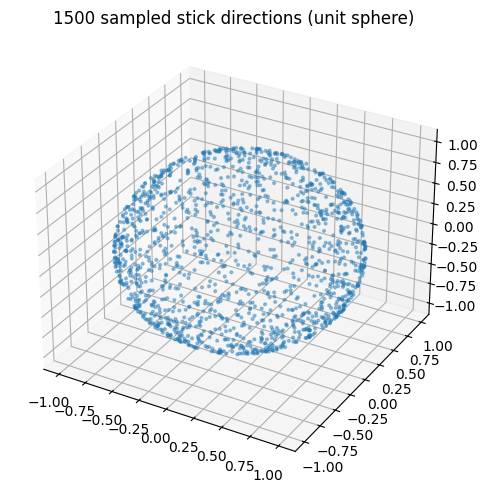

  [OK] Figure saved: direction_sampling_isotropy.png


'<project_root>/utils/../experiments/exp_795/direction_sampling_isotropy.png'

In [6]:
dirs = run_isotropy_check(n_samples=20000, seed=0)

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection='3d')
sample = dirs[:1500]
ax.scatter(sample[:,0], sample[:,1], sample[:,2], s=4, alpha=0.4)
ax.set_title("1500 sampled stick directions (unit sphere)")
plt.tight_layout()
plt.show()
exp_manager.save_figure(fig, "direction_sampling_isotropy.png")


---
## 3. Unit tests: hand-checkable R_eff

Small, hand-built 3D networks where the equivalent resistance is known in advance, to validate the full pipeline (contact detection -> percolation -> pruning -> boundary merge -> Laplacian solve) end-to-end.

### 3.1 Single edge

One long "backbone" stick plus two short "tabs" that cross it near x=0 and x=1 (each tab and the backbone touch at distance 0). This creates exactly one resistor between the merged source and drain nodes, so R_eff must equal k exactly.

In [7]:
points_1, points_2, expected_single, label_single = build_single_edge_case()
res_single = run_full_pipeline_3d(points_1, points_2, N=len(points_1), a=0.9, contact_distance=1e-6, k=1000.0, verbose=True)

print(f"\nhas_percolation: {res_single['has_percolation']}")
print(f"R_eff: {res_single['impedance']:.4f} Ohm  (expected: {expected_single:.4f} Ohm)")
assert res_single["has_percolation"]
assert abs(res_single["impedance"] - expected_single) < 1e-6
print(f"OK: {label_single} matches the hand-computed value exactly")



  Network 3D
  Sticks: 3,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 2
  Source nodes (x<0.1): 1
  Drain  nodes (x>0.9): 1
  Percolating paths: 1
  Edges before pruning: 1
  ✓ No dead-end nodes found. Network is already clean.
  Edges after  pruning: 1

  >>> Impedance = 1000.0000 Ohm <<<

has_percolation: True
R_eff: 1000.0000 Ohm  (expected: 1000.0000 Ohm)
OK: Single edge matches the hand-computed value exactly


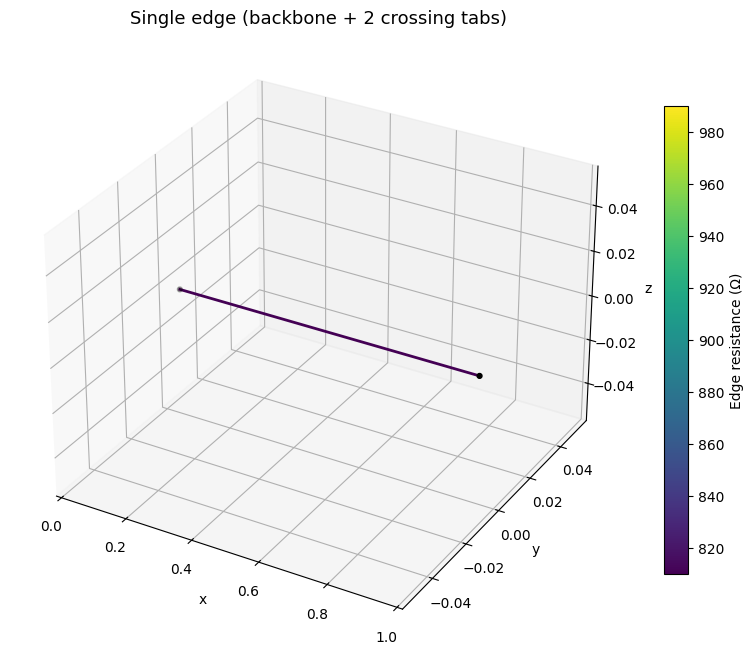

  [OK] Figure saved: single_edge_3d_network.png


'<project_root>/utils/../experiments/exp_795/single_edge_3d_network.png'

In [8]:
rl_single = distance_dependent_impedance(res_single, R0=1000.0)
fig = plot_network_3d_colored_by_resistance(
    res_single["merged_intersections"], res_single["merged_segment_to_nodes"],
    rl_single["edge_resistances"], title="Single edge (backbone + 2 crossing tabs)"
)
plt.show()
exp_manager.save_figure(fig, "single_edge_3d_network.png")


### 3.2 3D ladder

Two parallel "rails" offset along z (not just y), plus two "rungs" connecting them near the source and drain. Since both rails independently span source-to-drain, this is two identical resistors in parallel: R_eff = k/2. Displacing the rails in *z* (not just in the xy-plane) specifically checks that the graph/Laplacian layer really is ignoring the third coordinate, not just tolerating it.

In [9]:
points_1, points_2, expected_ladder, label_ladder = build_ladder_case()
res_ladder = run_full_pipeline_3d(points_1, points_2, N=len(points_1), a=0.9, contact_distance=1e-6, k=1000.0, verbose=True)

print(f"\nhas_percolation: {res_ladder['has_percolation']}")
print(f"R_eff: {res_ladder['impedance']:.4f} Ohm  (expected: {expected_ladder:.4f} Ohm)")
assert res_ladder["has_percolation"]
assert abs(res_ladder["impedance"] - expected_ladder) < 1e-6
print(f"OK: {label_ladder} matches the hand-computed parallel-resistor value exactly")



  Network 3D
  Sticks: 4,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 4
  Source nodes (x<0.1): 2
  Drain  nodes (x>0.9): 2
  Percolating paths: 1
  Edges before pruning: 4
  ✓ No dead-end nodes found. Network is already clean.
  Edges after  pruning: 4

  >>> Impedance = 500.0000 Ohm <<<

has_percolation: True
R_eff: 500.0000 Ohm  (expected: 500.0000 Ohm)
OK: 3D ladder matches the hand-computed parallel-resistor value exactly


Note: `merge_boundary_nodes` collapses every edge that connects source directly to drain (with no internal waypoint) into ONE edge with a conductance multiplier -- correct for R_eff (conductances add), but it means the *merged* network used for the circuit solve only has 2 nodes here, losing the rails' spatial distinctness. The plot below instead uses the pre-merge, post-pruning geometry (`intersections_points` + `filtered_segment_edge_list`), which still has both rails at their real z-offset.

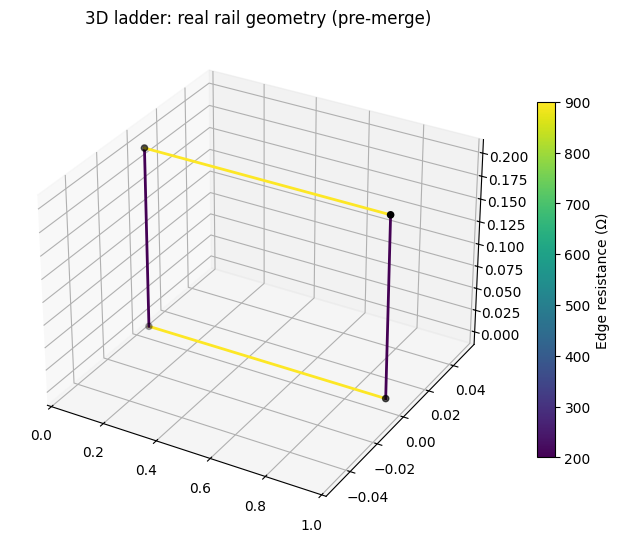

  [OK] Figure saved: ladder_3d_network.png


'<project_root>/utils/../experiments/exp_795/ladder_3d_network.png'

In [10]:
fig = plot_pre_merge_geometry_3d(res_ladder, title="3D ladder: real rail geometry (pre-merge)")
plt.show()
exp_manager.save_figure(fig, "ladder_3d_network.png")


### 3.3 Triple-parallel rails

Three parallel rails (offset in z), joined near the source and near the drain by two "rung" sticks that each span across all three rails' endpoints -- so each source/drain-side rung contributes one node per rail, and (since every rung-related node sits inside the merged source/drain region) any edges the rungs themselves would contribute are cancelled by the source/drain merge, exactly as in the ladder test. Three identical k-resistors in parallel: R_eff = k/3.

In [11]:
points_1, points_2, expected_triple, label_triple = build_triple_parallel_case()
res_triple = run_full_pipeline_3d(points_1, points_2, N=len(points_1), a=0.9, contact_distance=1e-6, k=1000.0, verbose=True)

print(f"\nhas_percolation: {res_triple['has_percolation']}")
print(f"R_eff: {res_triple['impedance']:.4f} Ohm  (expected: {expected_triple:.4f} Ohm)")
assert res_triple["has_percolation"]
assert abs(res_triple["impedance"] - expected_triple) < 1e-6
print(f"OK: {label_triple} match the hand-computed value exactly")



  Network 3D
  Sticks: 5,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 6
  Source nodes (x<0.1): 3
  Drain  nodes (x>0.9): 3
  Percolating paths: 1
  Edges before pruning: 7
  ✓ No dead-end nodes found. Network is already clean.
  Edges after  pruning: 7

  >>> Impedance = 333.3333 Ohm <<<

has_percolation: True
R_eff: 333.3333 Ohm  (expected: 333.3333 Ohm)
OK: Triple-parallel rails match the hand-computed value exactly


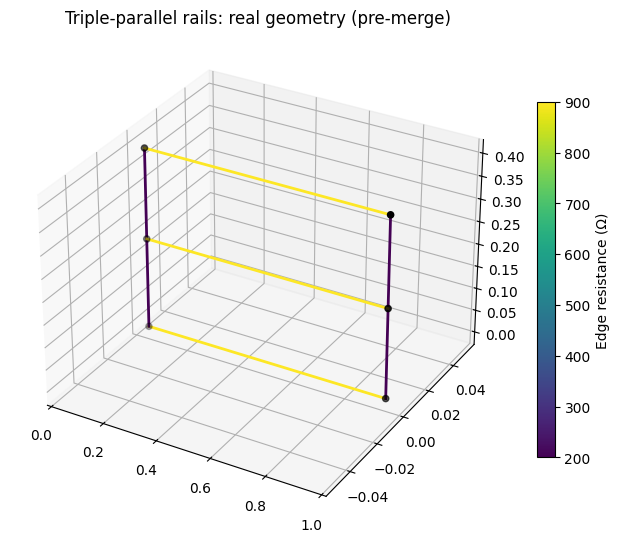

  [OK] Figure saved: triple_parallel_3d_network.png


'<project_root>/utils/../experiments/exp_795/triple_parallel_3d_network.png'

In [12]:
fig = plot_pre_merge_geometry_3d(res_triple, title="Triple-parallel rails: real geometry (pre-merge)")
plt.show()
exp_manager.save_figure(fig, "triple_parallel_3d_network.png")


### 3.4 Three-branch star

One direct backbone (source-to-drain in a single edge) plus two independent two-edge paths through separate internal waypoints W1, W2 (each waypoint formed by two sticks crossing each other directly -- no shared "hub" stick needed, since a waypoint only has degree 2). Three parallel branches: R1=k (direct), R2=R3=2k (two edges in series each). R_eff = 1/(1/k + 1/(2k) + 1/(2k)) = k/2.

In [13]:
points_1, points_2, expected_star, label_star = build_three_branch_star_case()
res_star = run_full_pipeline_3d(points_1, points_2, N=len(points_1), a=0.9, contact_distance=1e-6, k=1000.0, verbose=True)

print(f"\nhas_percolation: {res_star['has_percolation']}")
print(f"R_eff: {res_star['impedance']:.4f} Ohm  (expected: {expected_star:.4f} Ohm -- direct k || 2k || 2k)")
assert res_star["has_percolation"]
assert abs(res_star["impedance"] - expected_star) < 1e-6
print(f"OK: {label_star} matches the hand-computed value exactly")



  Network 3D
  Sticks: 7,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 8
  Source nodes (x<0.1): 3
  Drain  nodes (x>0.9): 3
  Percolating paths: 1
  Edges before pruning: 9
  ✓ No dead-end nodes found. Network is already clean.
  Edges after  pruning: 9

  >>> Impedance = 500.0000 Ohm <<<

has_percolation: True
R_eff: 500.0000 Ohm  (expected: 500.0000 Ohm -- direct k || 2k || 2k)
OK: Three-branch star matches the hand-computed value exactly


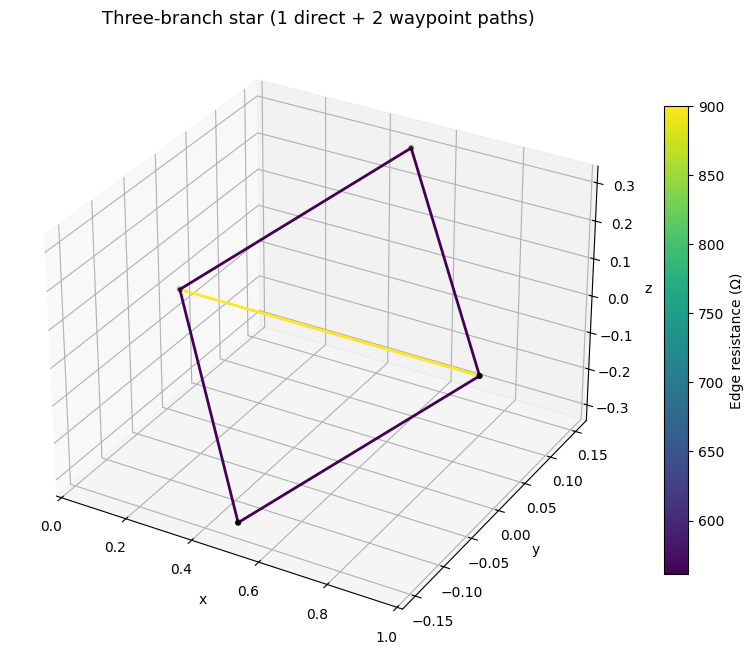

  [OK] Figure saved: three_branch_star_3d_network.png


'<project_root>/utils/../experiments/exp_795/three_branch_star_3d_network.png'

In [14]:
rl_star = distance_dependent_impedance(res_star, R0=1000.0)
fig = plot_network_3d_colored_by_resistance(
    res_star["merged_intersections"], res_star["merged_segment_to_nodes"],
    rl_star["edge_resistances"], title="Three-branch star (1 direct + 2 waypoint paths)"
)
plt.show()
exp_manager.save_figure(fig, "three_branch_star_3d_network.png")


### 3.5 Dangling branch / dead-end pruning

A backbone split into two series edges (S-mid, mid-D) by one crossing stick, matching a plain "two resistors in series" baseline (R=2k). Then the SAME network plus one additional stick that touches the backbone at the exact same mid point and continues on to a dead end (capped by a stick that touches nothing else) -- a genuine degree-1 internal node that `prune_dead_end_nodes` must remove. R_eff must come out identical to the no-stub baseline, and the stub must carry no current.

In [15]:
points_1_clean, points_2_clean, points_1_dangling, points_2_dangling, expected_dangling = build_dangling_branch_case()

res_clean = run_full_pipeline_3d(points_1_clean, points_2_clean, N=len(points_1_clean), a=0.9, contact_distance=1e-6, k=1000.0, verbose=False)
print(f"baseline (2 edges in series, no stub):  R_eff={res_clean['impedance']:.4f} Ohm  (expected {expected_dangling})")
assert abs(res_clean["impedance"] - expected_dangling) < 1e-6

res_dangling = run_full_pipeline_3d(points_1_dangling, points_2_dangling, N=len(points_1_dangling), a=0.9, contact_distance=1e-6, k=1000.0, verbose=True)

print(f"\nwith dangling branch:  R_eff={res_dangling['impedance']:.4f} Ohm  (expected {expected_dangling}, unchanged)")
assert res_dangling["has_percolation"]
assert abs(res_dangling["impedance"] - expected_dangling) < 1e-6
assert abs(res_dangling["impedance"] - res_clean["impedance"]) < 1e-9
print("OK: dangling branch was pruned and R_eff is identical to the no-stub baseline")


baseline (2 edges in series, no stub):  R_eff=2000.0000 Ohm  (expected 2000.0)

  Network 3D
  Sticks: 5,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 4
  Source nodes (x<0.1): 1
  Drain  nodes (x>0.9): 1
  Percolating paths: 1
  Edges before pruning: 3
  Iteration 1.1: removing 1 dead-end node(s) = 1 edge(s)
    → Dead-end nodes: [3 (0.500,0.300)...]
    → Remaining edges: 2

  ✓ Pruning complete: 1 node(s) and 1 edge(s) removed across 1 outer iteration(s).
  ✓ Verified: No internal dead-ends remain.
  Edges after  pruning: 2

  >>> Impedance = 2000.0000 Ohm <<<

with dangling branch:  R_eff=2000.0000 Ohm  (expected 2000.0, unchanged)
OK: dangling branch was pruned and R_eff is identical to the no-stub baseline


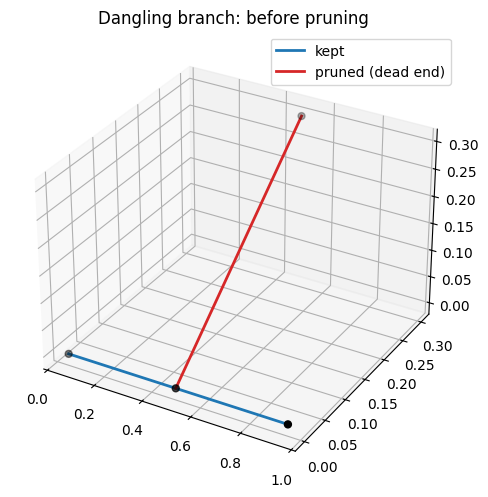

  [OK] Figure saved: dangling_branch_before_pruning.png


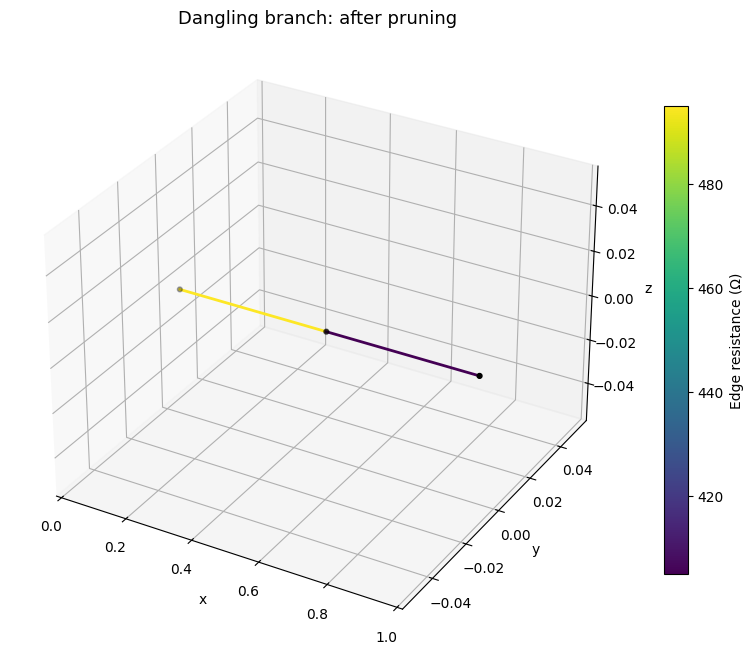

  [OK] Figure saved: dangling_branch_after_pruning.png


'<project_root>/utils/../experiments/exp_795/dangling_branch_after_pruning.png'

In [16]:
fig = plot_pruning_comparison_3d(res_dangling, title="Dangling branch: before pruning")
plt.show()
exp_manager.save_figure(fig, "dangling_branch_before_pruning.png")

rl_dangling = distance_dependent_impedance(res_dangling, R0=1000.0)
fig2 = plot_network_3d_colored_by_resistance(
    res_dangling["merged_intersections"], res_dangling["merged_segment_to_nodes"],
    rl_dangling["edge_resistances"], title="Dangling branch: after pruning"
)
plt.show()
exp_manager.save_figure(fig2, "dangling_branch_after_pruning.png")


### 3.6 Wheatstone bridge (genuine cycle topology)

All previous hand-built cases are pure series/parallel combinations. A Wheatstone bridge (S-A, S-B, A-D, B-D, plus a bridging A-B edge) is the simplest topology that is **not** series/parallel reducible -- it contains a real cycle and forces the full Laplacian solve.

Building two genuine degree-3 junctions (A and B) from pairwise stick contacts requires a small "hub" stick at each junction, touched by its three arms at three distinct (but very close) points -- this hub itself becomes 2 extra tiny edges, made negligible by using the distance-dependent resistance model with a hub length of ~0.001 (so its own resistance contribution is <0.1 Ohm, far below the ~300-700 Ohm arms).

Because the five arm lengths here are deliberately *not* symmetric, there's no shortcut hand formula -- so this is cross-checked independently via the pseudoinverse of the weighted graph Laplacian (`R_eff = (e_s - e_d)^T L^+ (e_s - e_d)`), the same style of independent check `distance_dependent_resistance.ipynb` used in 2D. Two independent methods (this project's `ImpedanceCalculator` vs. a from-scratch pseudoinverse) agreeing to ~1e-10 is strong evidence the cycle is being solved correctly.

In [17]:
R0_bridge = 1000.0
points_1, points_2, label_bridge = build_wheatstone_bridge_case()

res_bridge = run_full_pipeline_3d(points_1, points_2, N=len(points_1), a=0.9,
                                  contact_distance=1e-6, k=1000.0, verbose=True)
rl_bridge = distance_dependent_impedance(res_bridge, R0=R0_bridge)
R_pinv = effective_resistance_pinv(
    res_bridge["merged_intersections"], res_bridge["merged_segment_to_nodes"],
    res_bridge["merged_source_node"], res_bridge["merged_drain_node"],
    R0=R0_bridge, edge_conductance=res_bridge["edge_conductance"],
)

print(f"\nhas_percolation: {res_bridge['has_percolation']}   n_contacts: {len(res_bridge['intersections_points'])}")
print(f"ImpedanceCalculator R_eff:  {rl_bridge['impedance']:.6f} Ohm")
print(f"Independent pinv R_eff:     {R_pinv:.6f} Ohm")
print(f"difference:                 {abs(rl_bridge['impedance'] - R_pinv):.2e} Ohm")

assert res_bridge["has_percolation"]
assert abs(rl_bridge["impedance"] - R_pinv) < 1e-6
print(f"OK: {label_bridge} (genuine cycle) matches the independent pseudoinverse calculation")



  Network 3D
  Sticks: 9,  a = 0.9000,  contact_distance = 0.0000
  Contacts found: 10
  Source nodes (x<0.1): 2
  Drain  nodes (x>0.9): 2
  Percolating paths: 1
  Edges before pruning: 11
  ✓ No dead-end nodes found. Network is already clean.
  Edges after  pruning: 11

  >>> Impedance = 2000.0000 Ohm <<<

has_percolation: True   n_contacts: 10
ImpedanceCalculator R_eff:  493.368187 Ohm
Independent pinv R_eff:     493.368187 Ohm
difference:                 1.37e-11 Ohm
OK: Wheatstone bridge (genuine cycle) matches the independent pseudoinverse calculation


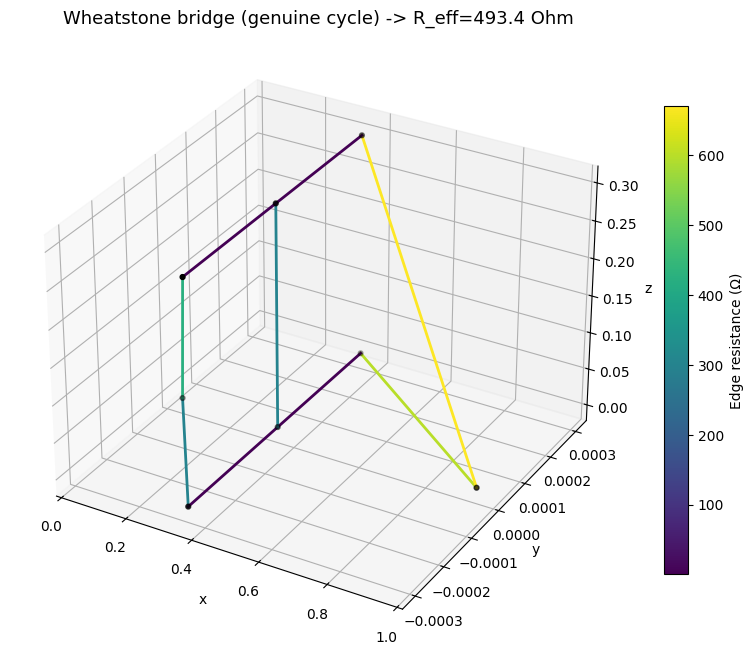

  [OK] Figure saved: wheatstone_bridge_3d_network.png


'<project_root>/utils/../experiments/exp_795/wheatstone_bridge_3d_network.png'

In [18]:
fig = plot_network_3d_colored_by_resistance(
    res_bridge["merged_intersections"], res_bridge["merged_segment_to_nodes"],
    rl_bridge["edge_resistances"],
    title=f"Wheatstone bridge (genuine cycle) -> R_eff={rl_bridge['impedance']:.1f} Ohm"
)
plt.show()
exp_manager.save_figure(fig, "wheatstone_bridge_3d_network.png")


---
## 4. Cross-check against the 2D pipeline (planar case)

The strongest regression test: take a real random 2D network that percolates under the original 2D pipeline, embed it in 3D by setting z=0 everywhere, and run it through the brand-new 3D pipeline with a near-zero `contact_distance`. If the 3D generalization is faithful, both pipelines must agree exactly.

In [19]:
N, a_2d = 60, 0.6
seed = 0
np.random.seed(seed)
points_1_2d, points_2_2d, angles_2d = [], [], []
generate_points(N, points_1_2d, points_2_2d, angles_2d, a_2d, enforce_bounds=True)

res_2d = run_full_pipeline(points_1_2d, points_2_2d, angles_2d, N, a_2d, k=1000.0, verbose=False)
print(f"2D pipeline:  percolates={res_2d['has_percolation']}  R_eff={res_2d['impedance']:.4f} Ohm")
assert res_2d["has_percolation"], "pick a different seed if this fails to percolate"

points_1_3d = [(p[0], p[1], 0.0) for p in points_1_2d]
points_2_3d = [(p[0], p[1], 0.0) for p in points_2_2d]
res_3d = run_full_pipeline_3d(points_1_3d, points_2_3d, N=N, a=a_2d, contact_distance=1e-9, k=1000.0, verbose=False)
print(f"3D pipeline:  percolates={res_3d['has_percolation']}  R_eff={res_3d['impedance']:.4f} Ohm")

rl_2d = distance_dependent_impedance(res_2d, R0=1000.0)
rl_3d = distance_dependent_impedance(res_3d, R0=1000.0)
print(f"\ndistance-dependent R:  2D={rl_2d['impedance']:.4f} Ohm   3D={rl_3d['impedance']:.4f} Ohm")

assert abs(res_2d["impedance"] - res_3d["impedance"]) < 1e-6
assert abs(rl_2d["impedance"] - rl_3d["impedance"]) < 1e-6
print("\nOK: the 3D pipeline reduces EXACTLY to the 2D pipeline in the planar case")


2D pipeline:  percolates=True  R_eff=3102.2478 Ohm


3D pipeline:  percolates=True  R_eff=3102.2478 Ohm



distance-dependent R:  2D=273.0641 Ohm   3D=273.0641 Ohm

OK: the 3D pipeline reduces EXACTLY to the 2D pipeline in the planar case


---
## 5. Application to a real random 3D network

Generate an actual random 3D stick network (isotropic directions, contact-based connectivity), confirm it percolates, compute R_eff under both resistance models, and visualize it in 3D.

### 5.1 Baseline

Percolating network found on attempt 6
  Contacts (nodes): 144
  Uniform R:             3564.8720 Ohm
  Distance-dependent R:  480.3719 Ohm


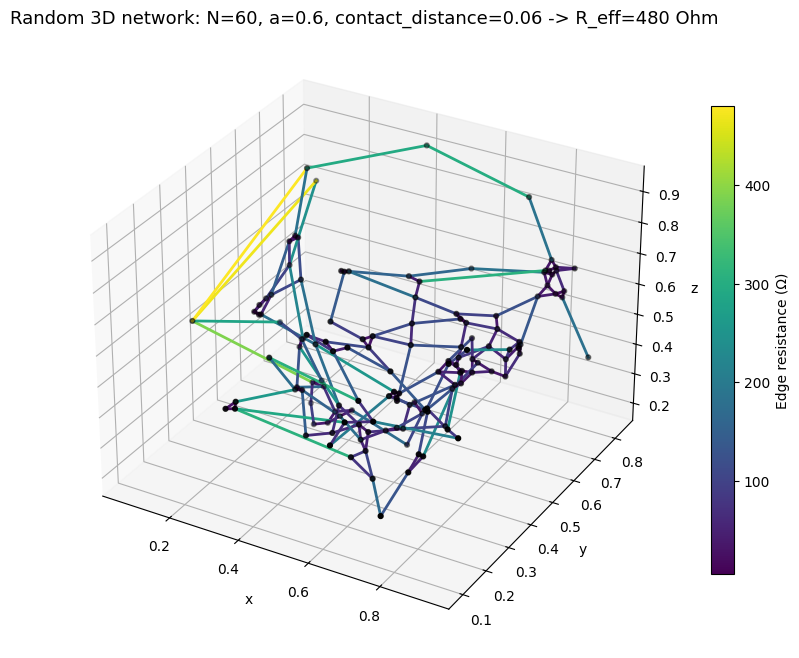

  [OK] Figure saved: random_network_3d.png
  [OK] JSON saved: random_network_3d.json


'<project_root>/utils/../experiments/exp_795/random_network_3d.json'

In [20]:
N_random, a, contact_distance = 60, 0.6, 0.06
R0 = 1000.0

res_random, attempts = generate_percolating_network_3d(
    N=N_random, a=a, contact_distance=contact_distance, k_uniform=R0, max_attempts=300, seed=1
)

print(f"Percolating network found on attempt {attempts}")
print(f"  Contacts (nodes): {len(res_random['intersections_points'])}")
print(f"  Uniform R:             {res_random['impedance']:.4f} Ohm")

rl_random = distance_dependent_impedance(res_random, R0)
print(f"  Distance-dependent R:  {rl_random['impedance']:.4f} Ohm")

fig = plot_network_3d_colored_by_resistance(
    res_random["merged_intersections"], res_random["merged_segment_to_nodes"],
    rl_random["edge_resistances"],
    title=f"Random 3D network: N={N_random}, a={a}, contact_distance={contact_distance} -> R_eff={rl_random['impedance']:.0f} Ohm"
)
plt.show()
exp_manager.save_figure(fig, "random_network_3d.png")
exp_manager.save_network(N_random, a, res_random["points_1"], res_random["points_2"], res_random["directions"],
                         filename="random_network_3d.json")


### 5.2 Denser connectivity (larger `contact_distance`)

Same N and a as the baseline, but a much larger `contact_distance` (0.15 instead of 0.06) -- physically, thicker sticks. More contacts per stick, lower R_eff, and the network percolates on essentially the first draw.

Percolating network found on attempt 1
  Contacts (nodes): 334
  Uniform R:             783.0308 Ohm
  Distance-dependent R:  110.1303 Ohm


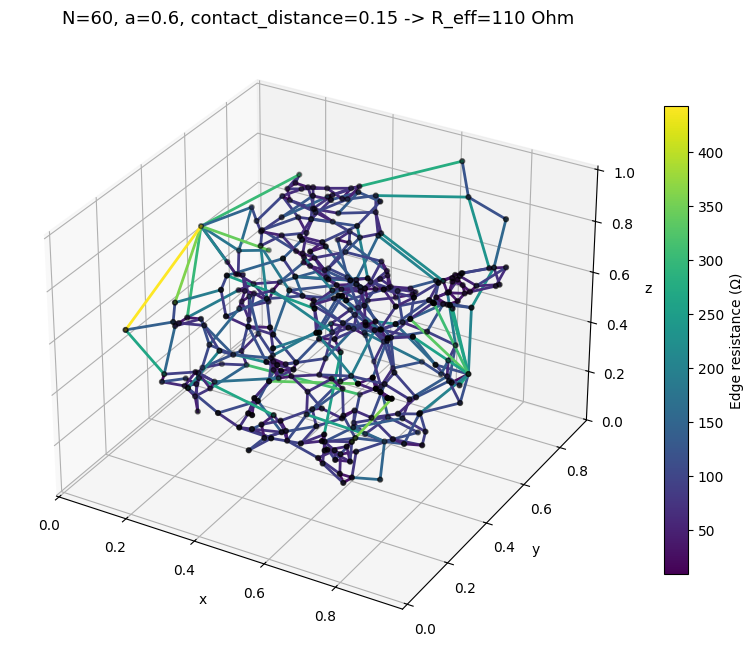

  [OK] Figure saved: random_network_3d_denser_contact.png


'<project_root>/utils/../experiments/exp_795/random_network_3d_denser_contact.png'

In [21]:
N_denser_contact, a_denser_contact, cd_denser_contact = 60, 0.6, 0.15

res_denser_contact, attempts_dc = generate_percolating_network_3d(
    N=N_denser_contact, a=a_denser_contact, contact_distance=cd_denser_contact,
    k_uniform=R0, max_attempts=300, seed=2
)

print(f"Percolating network found on attempt {attempts_dc}")
print(f"  Contacts (nodes): {len(res_denser_contact['intersections_points'])}")
print(f"  Uniform R:             {res_denser_contact['impedance']:.4f} Ohm")

rl_denser_contact = distance_dependent_impedance(res_denser_contact, R0)
print(f"  Distance-dependent R:  {rl_denser_contact['impedance']:.4f} Ohm")

fig = plot_network_3d_colored_by_resistance(
    res_denser_contact["merged_intersections"], res_denser_contact["merged_segment_to_nodes"],
    rl_denser_contact["edge_resistances"],
    title=f"N={N_denser_contact}, a={a_denser_contact}, contact_distance={cd_denser_contact} -> R_eff={rl_denser_contact['impedance']:.0f} Ohm"
)
plt.show()
exp_manager.save_figure(fig, "random_network_3d_denser_contact.png")


### 5.3 Denser network (larger N)

Same a and contact_distance as the baseline, but N=100 instead of 60 -- more sticks packed into the same unit cube, so more contacts, a richer graph, and a lower R_eff.

Percolating network found on attempt 1
  Contacts (nodes): 335
  Uniform R:             1868.3382 Ohm
  Distance-dependent R:  267.4672 Ohm


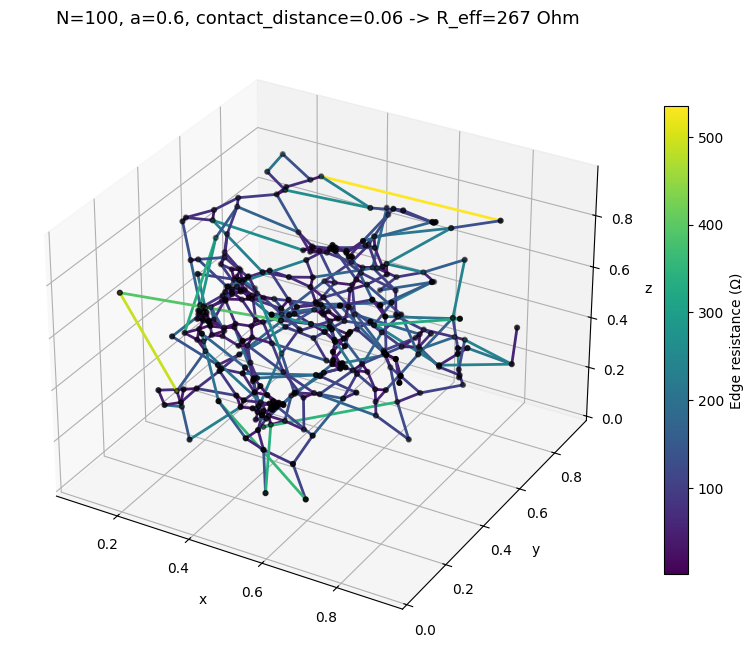

  [OK] Figure saved: random_network_3d_denser_N.png


'<project_root>/utils/../experiments/exp_795/random_network_3d_denser_N.png'

In [22]:
N_dense, a_dense, cd_dense = 100, 0.6, 0.06

res_dense, attempts_dense = generate_percolating_network_3d(
    N=N_dense, a=a_dense, contact_distance=cd_dense, k_uniform=R0, max_attempts=300, seed=3
)

print(f"Percolating network found on attempt {attempts_dense}")
print(f"  Contacts (nodes): {len(res_dense['intersections_points'])}")
print(f"  Uniform R:             {res_dense['impedance']:.4f} Ohm")

rl_dense = distance_dependent_impedance(res_dense, R0)
print(f"  Distance-dependent R:  {rl_dense['impedance']:.4f} Ohm")

fig = plot_network_3d_colored_by_resistance(
    res_dense["merged_intersections"], res_dense["merged_segment_to_nodes"],
    rl_dense["edge_resistances"],
    title=f"N={N_dense}, a={a_dense}, contact_distance={cd_dense} -> R_eff={rl_dense['impedance']:.0f} Ohm"
)
plt.show()
exp_manager.save_figure(fig, "random_network_3d_denser_N.png")


### 5.4 Sparse / near-percolation-threshold network

Fewer, shorter sticks and a tighter `contact_distance` (N=50, a=0.5, contact_distance=0.04) -- close enough to the percolation threshold that `generate_percolating_network_3d` needs many more draws before it finds one that percolates (compare `attempts` here to the baseline's).

Percolating network found on attempt 47  (baseline needed only 6)
  Contacts (nodes): 43
  Uniform R:             10870.9440 Ohm
  Distance-dependent R:  2567.1308 Ohm


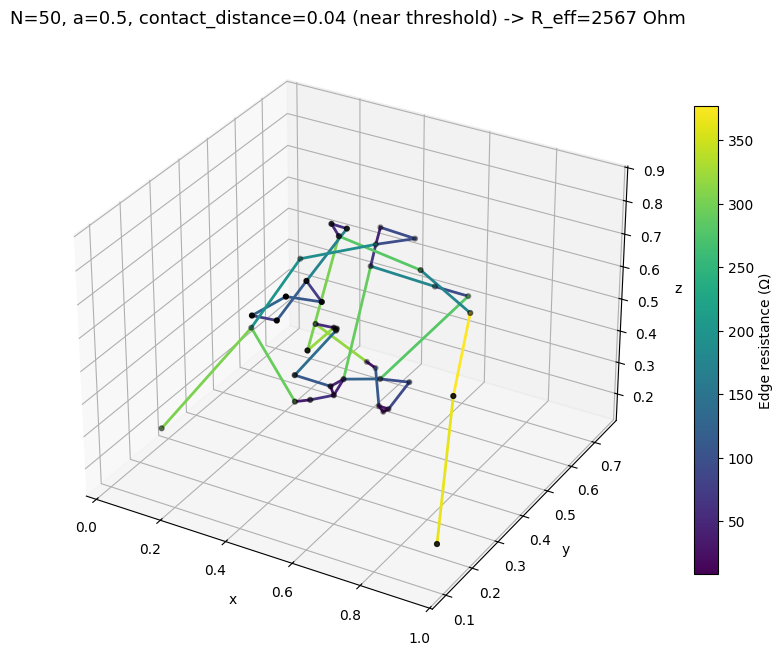

  [OK] Figure saved: random_network_3d_sparse.png


'<project_root>/utils/../experiments/exp_795/random_network_3d_sparse.png'

In [23]:
N_sparse, a_sparse, cd_sparse = 50, 0.5, 0.04

res_sparse, attempts_sparse = generate_percolating_network_3d(
    N=N_sparse, a=a_sparse, contact_distance=cd_sparse, k_uniform=R0, max_attempts=500, seed=0
)

print(f"Percolating network found on attempt {attempts_sparse}  (baseline needed only {attempts})")
print(f"  Contacts (nodes): {len(res_sparse['intersections_points'])}")
print(f"  Uniform R:             {res_sparse['impedance']:.4f} Ohm")

rl_sparse = distance_dependent_impedance(res_sparse, R0)
print(f"  Distance-dependent R:  {rl_sparse['impedance']:.4f} Ohm")

fig = plot_network_3d_colored_by_resistance(
    res_sparse["merged_intersections"], res_sparse["merged_segment_to_nodes"],
    rl_sparse["edge_resistances"],
    title=f"N={N_sparse}, a={a_sparse}, contact_distance={cd_sparse} (near threshold) -> R_eff={rl_sparse['impedance']:.0f} Ohm"
)
plt.show()
exp_manager.save_figure(fig, "random_network_3d_sparse.png")


### 5.5 Monte Carlo across many random realizations

Same (N, a, contact_distance) as the baseline, drawn 10 times -- how consistent is the ratio between the two resistance models across independent random networks?

In [24]:
n_trials_mc = 10
uniform_list, dist_list = [], []
for trial in range(n_trials_mc):
    res_mc, _ = generate_percolating_network_3d(
        N=N_random, a=a, contact_distance=contact_distance, k_uniform=R0, max_attempts=300, seed=100 + trial
    )
    rl_mc = distance_dependent_impedance(res_mc, R0)
    uniform_list.append(res_mc["impedance"])
    dist_list.append(rl_mc["impedance"])

uniform_arr = np.array(uniform_list)
dist_arr = np.array(dist_list)
ratio = dist_arr / uniform_arr

print(f"Over {n_trials_mc} realizations of N={N_random}, a={a}, contact_distance={contact_distance}:")
print(f"  Uniform R:              mean={uniform_arr.mean():8.1f}  std={uniform_arr.std():7.1f} Ohm")
print(f"  Distance-dependent R:   mean={dist_arr.mean():8.1f}  std={dist_arr.std():7.1f} Ohm")
print(f"  Ratio (dist/uniform):   mean={ratio.mean():.4f}  std={ratio.std():.4f}")


Over 10 realizations of N=60, a=0.6, contact_distance=0.06:
  Uniform R:              mean=  3086.7  std=  949.4 Ohm
  Distance-dependent R:   mean=   482.3  std=  203.5 Ohm
  Ratio (dist/uniform):   mean=0.1554  std=0.0322


### 5.6 Dead-end detection and removal (5 real random networks)

Real random networks -- not hand-built ones -- always have some sticks that touch the percolating cluster but don't lead anywhere useful (branches with a genuine degree-1 internal endpoint). `prune_dead_end_nodes` removes them before the circuit is solved, exactly as demonstrated by hand in section 3.5. Small, sparse networks (N=25) are used here so the removed branches are actually visible rather than lost among hundreds of edges.

seed=0: attempts=107  edges before/after pruning=35/32  (removed 3)  R_eff=4738.6 Ohm


seed=1: attempts=163  edges before/after pruning=38/34  (removed 4)  R_eff=5712.7 Ohm


seed=2: attempts=149  edges before/after pruning=37/35  (removed 2)  R_eff=4525.0 Ohm


seed=3: attempts=245  edges before/after pruning=21/16  (removed 5)  R_eff=6866.7 Ohm
seed=9: attempts= 84  edges before/after pruning=20/15  (removed 5)  R_eff=6461.5 Ohm


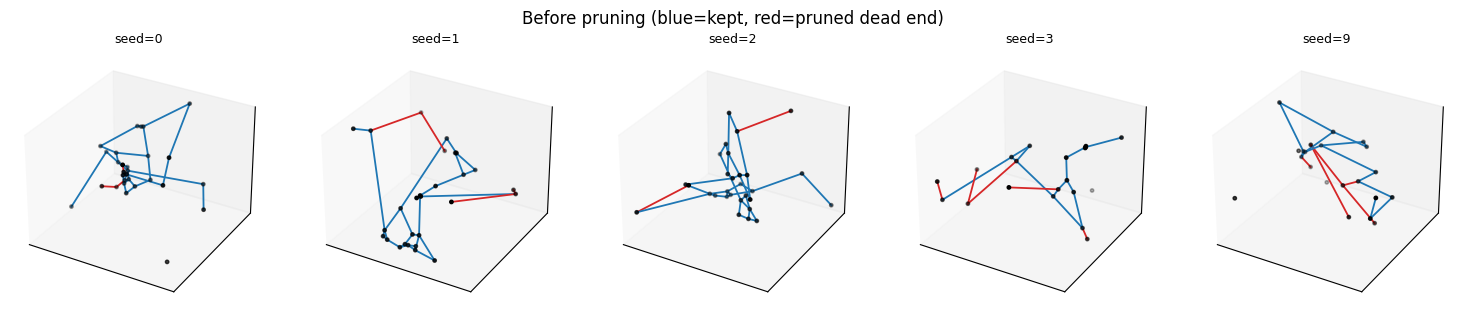

  [OK] Figure saved: dead_end_grid_before.png


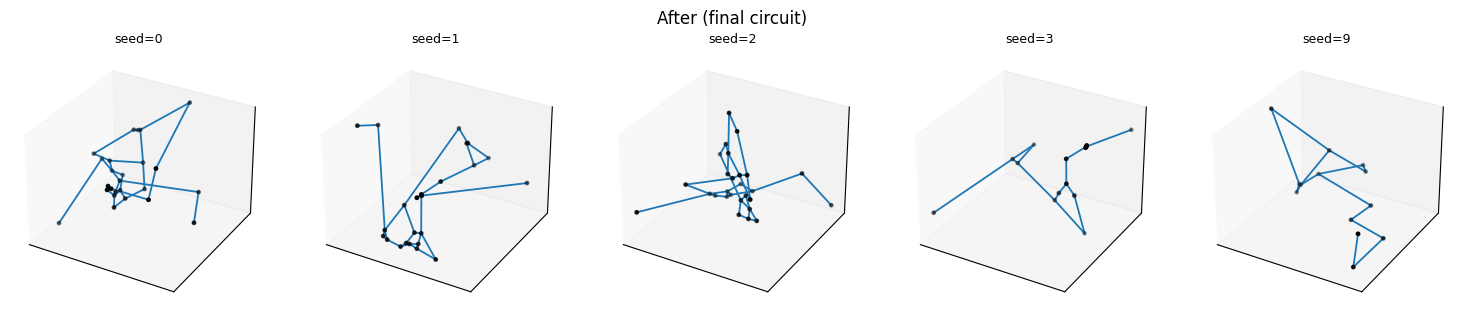

  [OK] Figure saved: dead_end_grid_after.png


'<project_root>/utils/../experiments/exp_795/dead_end_grid_after.png'

In [25]:
N_de, a_de, cd_de = 25, 0.6, 0.06
dead_end_seeds = [0, 1, 2, 3, 9]

dead_end_results = []
for s in dead_end_seeds:
    res, attempts_de = generate_percolating_network_3d(
        N=N_de, a=a_de, contact_distance=cd_de, k_uniform=1000.0, max_attempts=500, seed=s
    )
    removed = len(res["segment_edge_list"]) - len(res["filtered_segment_edge_list"])
    print(f"seed={s}: attempts={attempts_de:3d}  edges before/after pruning="
          f"{len(res['segment_edge_list']):2d}/{len(res['filtered_segment_edge_list']):2d}  "
          f"(removed {removed})  R_eff={res['impedance']:.1f} Ohm")
    dead_end_results.append(res)

titles = [f"seed={s}" for s in dead_end_seeds]
fig_before = plot_pruning_comparison_grid_3d(dead_end_results, titles=titles)
plt.show()
exp_manager.save_figure(fig_before, "dead_end_grid_before.png")

fig_after = plot_merged_network_grid_3d(dead_end_results, titles=titles)
plt.show()
exp_manager.save_figure(fig_after, "dead_end_grid_after.png")


### 5.7 Self-loop detection and removal (5 real random networks)

A self-loop here is an edge whose two endpoints end up mapped to the SAME final node -- which, in this pipeline, only happens when both endpoints sit inside the same merged boundary region (both within x<0.1, or both within x>0.9), since `merge_boundary_nodes` collapses each region into a single node. `identify_self_loop_edges` flags these pre-merge candidates; `merge_boundary_nodes` itself silently drops them (`if new_n1 == new_n2: continue`) -- verified below via `count_self_loops` on the final merged graph, which must always be 0. This mirrors the self-loop handling already established for the 2D pipeline (`utils/self_loop_utils.py`), reused here unchanged since it's purely topological.

seed=4: attempts= 37  self-loop candidates (pre-merge)=5  self-loops remaining after merge=0  R_eff=3809.5 Ohm
seed=5: attempts=  3  self-loop candidates (pre-merge)=4  self-loops remaining after merge=0  R_eff=5130.1 Ohm


seed=6: attempts=104  self-loop candidates (pre-merge)=3  self-loops remaining after merge=0  R_eff=5213.1 Ohm
seed=7: attempts= 50  self-loop candidates (pre-merge)=2  self-loops remaining after merge=0  R_eff=4729.4 Ohm


seed=8: attempts= 71  self-loop candidates (pre-merge)=2  self-loops remaining after merge=0  R_eff=15666.7 Ohm


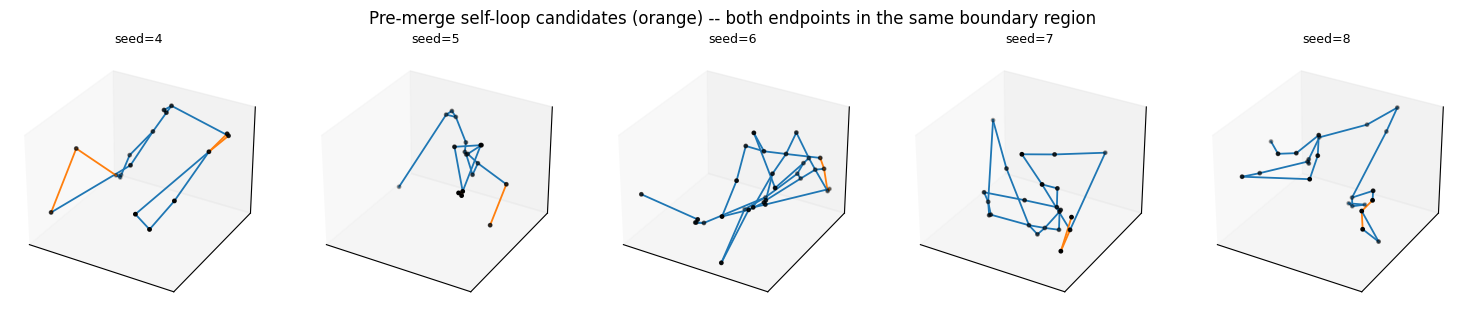

  [OK] Figure saved: self_loop_grid_before.png


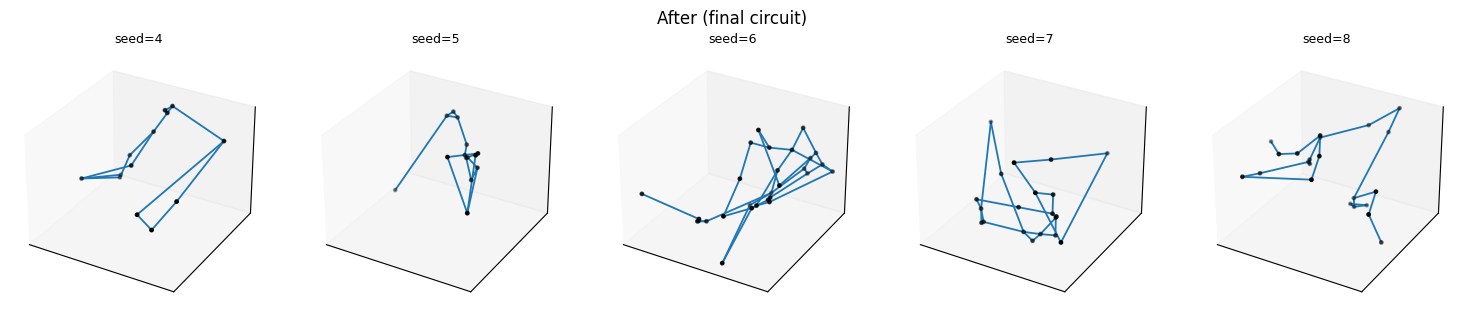

  [OK] Figure saved: self_loop_grid_after.png

OK: every self-loop candidate is gone from the final merged graph in all 5 cases


In [26]:
N_sl, a_sl, cd_sl = 25, 0.6, 0.06
self_loop_seeds = [4, 5, 6, 7, 8]

self_loop_results = []
for s in self_loop_seeds:
    res, attempts_sl = generate_percolating_network_3d(
        N=N_sl, a=a_sl, contact_distance=cd_sl, k_uniform=1000.0, max_attempts=500, seed=s
    )
    n_candidates = len(identify_self_loop_edges(res))
    n_remaining = count_self_loops(res["merged_segment_to_nodes"])
    print(f"seed={s}: attempts={attempts_sl:3d}  self-loop candidates (pre-merge)={n_candidates}  "
          f"self-loops remaining after merge={n_remaining}  R_eff={res['impedance']:.1f} Ohm")
    assert n_remaining == 0, "a self-loop survived merge_boundary_nodes!"
    self_loop_results.append(res)

titles = [f"seed={s}" for s in self_loop_seeds]
fig_before = plot_self_loop_grid_3d(self_loop_results, titles=titles)
plt.show()
exp_manager.save_figure(fig_before, "self_loop_grid_before.png")

fig_after = plot_merged_network_grid_3d(self_loop_results, titles=titles)
plt.show()
exp_manager.save_figure(fig_after, "self_loop_grid_after.png")

print("\nOK: every self-loop candidate is gone from the final merged graph in all 5 cases")


---
## 6. Small illustrative sweep: R_eff vs N

A small sweep at fixed `a` and `contact_distance`, just to check the qualitative trend (R_eff should decrease as N grows, same as the 2D sweeps). This is intentionally small -- a handful of N values, few trials each -- not the full (N, a, contact_distance) sweep that the 2D project ran in `effective_resistance_vs_N_a.ipynb`; a full 3D sweep is a natural follow-up notebook once this pipeline is validated, and is a good candidate for a larger run elsewhere (e.g. a cluster), mirroring how the 2D project scaled up its own sweeps.

In [27]:
N_values_3d = [40, 55, 70, 85]
a_fixed = 0.6
contact_distance_fixed = 0.06
n_trials_3d = 5
R0 = 1000.0

results_grid_3d = {}
for N in N_values_3d:
    R_effs = []
    for trial in range(n_trials_3d):
        res, attempts = generate_percolating_network_3d(
            N=N, a=a_fixed, contact_distance=contact_distance_fixed,
            k_uniform=R0, max_attempts=300, seed=1000 * N + trial
        )
        if res is not None:
            rl = distance_dependent_impedance(res, R0)
            R_effs.append(rl["impedance"])
    results_grid_3d[N] = R_effs
    mean_str = f"{np.mean(R_effs):8.1f}" if R_effs else "     n/a"
    print(f"N={N:3d}   {len(R_effs)}/{n_trials_3d} percolating   R_eff mean={mean_str} Ohm")


N= 40   5/5 percolating   R_eff mean=   756.2 Ohm


N= 55   5/5 percolating   R_eff mean=   917.7 Ohm
N= 70   5/5 percolating   R_eff mean=   521.0 Ohm


N= 85   5/5 percolating   R_eff mean=   245.2 Ohm


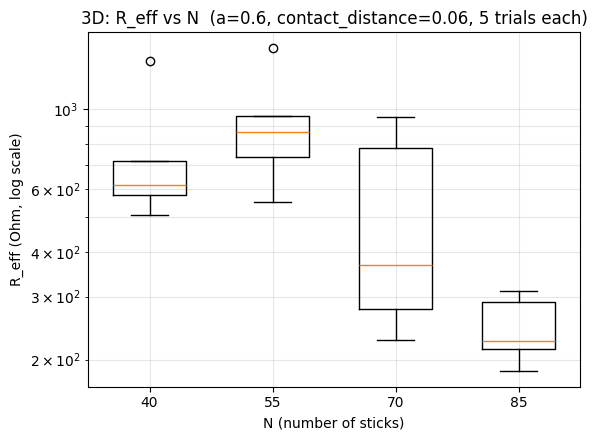

  [OK] Figure saved: box_R_eff_vs_N_3d.png


'<project_root>/utils/../experiments/exp_795/box_R_eff_vs_N_3d.png'

In [28]:
fig, ax = plt.subplots(figsize=(6, 4.5))
data = [results_grid_3d[N] for N in N_values_3d if results_grid_3d[N]]
labels = [N for N in N_values_3d if results_grid_3d[N]]
ax.boxplot(data, positions=range(len(labels)), widths=0.6)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_yscale('log')
ax.set_xlabel('N (number of sticks)')
ax.set_ylabel('R_eff (Ohm, log scale)')
ax.set_title(f'3D: R_eff vs N  (a={a_fixed}, contact_distance={contact_distance_fixed}, {n_trials_3d} trials each)')
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()
exp_manager.save_figure(fig, "box_R_eff_vs_N_3d.png")


---
## Notes

- The contact criterion (closest distance between finite segments <= `contact_distance`) replaces 2D's exact-intersection test; it has no unique intersection point, so each contact is placed at the **midpoint** of the two segments' closest-approach points -- a simplification whose error is of the same order as `contact_distance` itself.
- A physically richer model would instead treat each contact as **two** nodes (one per stick) joined by a small junction/contact resistance (as in tunneling-resistance models for real fiber composites) -- a natural follow-up notebook once this simpler version is validated, mirroring how `distance_dependent_resistance.ipynb` refined the original uniform-resistance model.
- `contact_gap` (the real closest-approach distance) is already saved per contact in `intersections_points`'s companion list, so that follow-up notebook won't need to recompute any geometry.
- The full (N, a, contact_distance) 3-parameter sweep -- the 3D analogue of `effective_resistance_vs_N_a.ipynb` -- is deliberately out of scope here; this notebook only checks the pipeline is correct and the qualitative N-trend is sane.

---
## 7. Save consolidated summary

In [29]:
summary = {
    "experiment": exp_manager.get_info(),
    "unit_tests": {
        "single_edge_impedance": res_single["impedance"],
        "ladder_impedance": res_ladder["impedance"],
        "planar_cross_check_2d_impedance": res_2d["impedance"],
        "planar_cross_check_3d_impedance": res_3d["impedance"],
    },
    "random_network": {
        "N": N_random, "a": a, "contact_distance": contact_distance,
        "attempts": attempts,
        "n_contacts": len(res_random["intersections_points"]),
        "uniform_impedance": res_random["impedance"],
        "distance_dependent_impedance": rl_random["impedance"],
    },
    "sweep": {
        "N_values": N_values_3d, "a": a_fixed, "contact_distance": contact_distance_fixed,
        "n_trials": n_trials_3d,
        "R_eff_by_N": {str(N): vals for N, vals in results_grid_3d.items()},
    },
}

exp_manager.save_json(summary, "percolation_3d_summary.json")

print(f"\nAll results saved to: {exp_manager.experiment_dir}")
for f in sorted(os.listdir(exp_manager.experiment_dir)):
    print(f"  - {f}")


  [OK] JSON saved: percolation_3d_summary.json

All results saved to: <project_root>/utils/../experiments/exp_795
  - box_R_eff_vs_N_3d.png
  - dangling_branch_after_pruning.png
  - dangling_branch_before_pruning.png
  - dead_end_grid_after.png
  - dead_end_grid_before.png
  - direction_sampling_isotropy.png
  - ladder_3d_network.png
  - percolation_3d_summary.json
  - random_network_3d.json
  - random_network_3d.png
  - random_network_3d_denser_N.png
  - random_network_3d_denser_contact.png
  - random_network_3d_sparse.png
  - self_loop_grid_after.png
  - self_loop_grid_before.png
  - single_edge_3d_network.png
  - three_branch_star_3d_network.png
  - triple_parallel_3d_network.png
  - wheatstone_bridge_3d_network.png
